# 10 - Sentence-level experiment: cascade, and how it compares with document level

The document-level regime asks a model for every participant of a whole article in
one query. The sentence-level regime splits the same job into three logged stages
run over one sentence at a time -- **detection** (does this sentence mention a
participant?), **extraction** (which spans?) and **classification** (what type is
each span?) -- and folds the per-sentence answers back into the document-level
answer format, so **both regimes are scored by the same code against the same
annotations**.

This notebook reuses the analyses already established elsewhere in this package and
points them at that regime:

1. **The cascade table** - the participant funnel of notebook 03, with the two
   sentence stages that precede it prepended.
2. **Sentence level against document level** - F1-ext and F1-cls for the same
   model, the same documents and the same temperature.
3. **Word-level position analysis** - the machinery of notebook 09, comparing where
   inside a participant each regime cuts.
4. **Class-level analysis** - the conditional typing accuracy of notebook 03,
   sentence level against the document-level field.

### Scope, and one asymmetry that shapes the comparison

The sentence-level experiment covers a single model, `qwen3_14b`, at a fixed
*T* = 0.3, in both languages, under two prompt conditions: `sent_exp` (one-shot
example) and `sent_def_exp` (example plus the definition of narrative participant).

That model reaches the document-level test stage on `ext_exp` - an
**extraction-only** variant - in both languages, and it is the only variant run for
it there. Two consequences, both load-bearing below:

* the **F1-ext** comparison is clean: same model, same documents, same prompt
  family, and *T* = 0.3 is available on both sides, so nothing but the regime
  differs;
* there is **no document-level F1-cls for `qwen3_14b` at all**. Its document-level
  runs predict no type anywhere. The class-level comparison in Section 4 therefore
  sets the sentence-level runs against the *pooled document-level classifying runs*
  - the eleven (model, language) runs of notebook 03 - and not against this model's
  own document-level counterpart, which does not exist.


In [1]:
import sys

sys.path.insert(0, ".")        # _common
sys.path.insert(0, "../..")    # project root: src/, experiments/

import ast
import contextlib
import difflib
import io
import json
from functools import lru_cache

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import _common as c
from experiments.constants import (
    WORD_CATEGORIES_EN,
    WORD_CATEGORIES_PT,
    word_to_category,
)
from src.utils import tokenize as _tokenize

plt.rcParams["figure.dpi"] = 110
pd.set_option("display.width", 200)

MODEL = "qwen3_14b"
VARIATION = "temp0.3_nodelim_norole_nocot"
CONDITIONS = ["sent_exp", "sent_def_exp"]
SENTENCE_TEMPERATURE = 0.3
OVERVIEW_DIR = c.RESULTS_DIR / "sentence_level" / "overview"

# The document-level run held against the sentence-level ones: same model, same
# documents, and the same temperature, so the regime is the only thing that moves.
DOC_TEMPLATE = "ext_exp"

# One colour per regime, reused by every figure below. Okabe-Ito, consistent with
# _common.py; the two sentence conditions keep the palette of notebook 06.
REGIME_COLORS = {
    "document": "#009E73",
    "sent_exp": "#0072B2",
    "sent_def_exp": "#D55E00",
}
REGIME_ORDER = ["document", "sent_exp", "sent_def_exp"]
REGIME_LABELS = {
    "document": "document (ext_exp)",
    "sent_exp": "sentence (sent_exp)",
    "sent_def_exp": "sentence (sent_def_exp)",
}

# --- notebook 09 word-level constants, unchanged so the two notebooks' figures can
# --- be read against each other.
OUTCOME_ORDER = ["tp", "fn", "fp"]
OUTCOME_LABELS = {
    "tp": "TP - word matched",
    "fn": "FN - annotation word missed",
    "fp": "FP - word added by the model",
}
OUTCOME_COLORS = {"tp": "#009E73", "fn": "#D55E00", "fp": "#0072B2"}

CATEGORY_COLORS = {
    "Articles & Determiners": "#0072B2",
    "Prepositions & Connectives": "#D55E00",
    "Generic Person Nouns": "#009E73",
    "Places & Facilities": "#CC79A7",
    "Organizations & Institutions": "#E69F00",
    "Other Content Words": "#56B4E9",
    "Names & other content": "#666666",
    "Other": "#BBBBBB",
}
CATEGORY_ORDER = list(CATEGORY_COLORS)

SURFACE = "#FFFFFF"   # drawn between stacked segments to keep them separable
ORDINALS = {1: "1st word", 2: "2nd word", 3: "3rd word", 4: "4th word", 5: "5th word"}
# `position_figure` labels its bar groups through this map. Notebook 09 groups by
# language; here the groups are regimes, so both sets of keys live in it.
SHORT_LANGUAGE = {
    "portuguese": "PT",
    "english": "EN",
    "document": "doc",
    "sent_exp": "s_exp",
    "sent_def_exp": "s_def",
}

## Helpers

`tokenize` is imported from the pipeline rather than reimplemented, so a "word" here
is exactly what the evaluator counted. The alignment replay, the lexical
categorisation and the two-panel position figure are carried over from notebook 09
unchanged - the figures in Section 3 are meant to be read directly against the ones
there, which only holds if the code that draws them is the same.

The pairing helpers -- `pairing_flags` and `inexact_only`, which restrict the word
rows to the participants a run did **not** recover exactly -- come from the same
place, with one change. Notebook 09 keys a pairing on `template`, which does not
separate the regimes here: the document-level run and `sent_exp` share the run name
`ext_exp_temp0.3_nodelim_norole_nocot` over the same documents, so `regime` is part
of the key below.


In [2]:
@lru_cache(maxsize=None)
def tokenize(text: str) -> tuple:
    """`src.utils.tokenize`, silenced (it prints on every call) and cached."""
    if not isinstance(text, str) or not text:
        return ()
    with contextlib.redirect_stdout(io.StringIO()):
        return tuple(_tokenize(text))


WORD_CATEGORIES = {"portuguese": WORD_CATEGORIES_PT, "english": WORD_CATEGORIES_EN}
UNLISTED = "Names & other content"


def categorize(token: str, language: str) -> str:
    """Re-derives a word's lexical category from the *current* constants.py.

    The `word_category` column stored in the CSVs was written by an earlier
    vocabulary -- Portuguese labels on the PT side ("Artigos"), a different English
    set on the EN side ("Articles") -- so as stored the two languages cannot be put
    on one axis. `constants.py` now maps both onto a single English label set;
    re-deriving here makes the PT and EN halves of a figure mean the same thing
    without re-running evaluation over every result tree. The stored column is kept
    as `word_category` for reference.
    """
    label = word_to_category(token, WORD_CATEGORIES[language])
    return UNLISTED if label == "Nao definido" else label


def _replay_alignment(pred_repr: str, ann_text: str) -> dict:
    """Recovers each word's slot in the annotation by replaying the scorer's diff.

    Mirrors `src/evaluate.py::macro_averaged_f1_score`: walk
    `difflib.ndiff(prediction_tokens, annotation_tokens)`, emit one record per word
    ('  ' -> tp, '- ' -> fp, '+ ' -> fn), and skip a token already seen for this
    prediction. The only addition is `slot`, the 1-based index into the annotation.

    Returns {token: (verdict, slot, annotation_length)}, deduplicated exactly as the
    pipeline does so it joins one-to-one onto the stored rows.
    """
    try:
        pred_tokens = list(ast.literal_eval(pred_repr))
    except (ValueError, SyntaxError):
        return {}
    ann_tokens = list(tokenize(ann_text))
    n_ann = len(ann_tokens)

    seen, recovered, slot = set(), {}, 0
    for line in difflib.ndiff(pred_tokens, ann_tokens):
        tag, token = line[:2], line[2:].strip()
        if tag == "  ":
            slot += 1
            verdict, position = "tp", slot
        elif tag == "+ ":
            slot += 1
            verdict, position = "fn", slot
        elif tag == "- ":
            # Not an annotation word: anchor it to the slot it aligns against.
            verdict, position = "fp", min(slot + 1, max(n_ann, 1))
        else:
            continue                       # '? ' hint lines
        if token not in seen:
            seen.add(token)
            recovered[token] = (verdict, position, n_ann)
    return recovered


def add_positions(df: pd.DataFrame) -> pd.DataFrame:
    """Adds `ann_pos`, `ann_len`, `category` and the replayed verdict to a
    detailed_results_token_level frame."""
    df = df.copy()
    df["matched_annotation"] = df["matched_annotation"].fillna("")
    alignments = {
        (pred, ann): _replay_alignment(pred, ann)
        for pred, ann in (df[["complete_prediction", "matched_annotation"]]
                          .drop_duplicates().itertuples(index=False))
    }
    recovered = [
        alignments[(pred, ann)].get(str(token), (None, None, None))
        for pred, ann, token in zip(df["complete_prediction"],
                                    df["matched_annotation"], df["token"])
    ]
    df[["replayed_result", "ann_pos", "ann_len"]] = pd.DataFrame(recovered, index=df.index)
    df["category"] = [categorize(str(token), language)
                      for token, language in zip(df["token"], df["language"])]
    return df


def check_replay(df: pd.DataFrame, name: str) -> None:
    """The replay must reproduce the pipeline's own verdict for every row."""
    unrecovered = int(df["replayed_result"].isna().sum())
    scored = df.dropna(subset=["replayed_result"])
    agreement = (scored["replayed_result"] == scored["result"]).mean()
    print(f"{name:<34} rows={len(df):>7}  unrecovered={unrecovered:>4} "
          f"({unrecovered / len(df):6.2%})  verdict agreement={agreement:8.4%}")
    assert agreement == 1.0, f"{name}: replay disagrees with the stored verdict"


# ---------------------------------------------------------------------------
# The participant as a unit: one scored (prediction -> annotation) pairing
# ---------------------------------------------------------------------------

# Notebook 09 keys a pairing on `template`; here that is not enough. The
# document-level run and the `sent_exp` run carry the *same* run name --
# `ext_exp_temp0.3_nodelim_norole_nocot` -- over the same documents, so without
# `regime` in the key the two regimes' pairings would collapse into one.
PAIRING_KEYS = ["language", "regime", "model", "doc_id", "template",
                "complete_prediction", "matched_annotation"]


def pairing_flags(df: pd.DataFrame) -> pd.DataFrame:
    """One row per scored (prediction -> annotation) pairing, with what it books.

    A pairing is the unit a *participant* is counted in: the words of one predicted
    span aligned against the one annotation the scorer matched it to.

    Pairings with an empty `matched_annotation` are dropped: a prediction that
    aligned to nothing is a spurious span, not a participant whose boundary went
    wrong. `exact` marks the pairings whose words are all `tp`.
    """
    flags = (
        df.assign(matched_annotation=df["matched_annotation"].fillna(""))
        .groupby(PAIRING_KEYS, sort=False)
        .agg(has_tp=("result", lambda s: (s == "tp").any()),
             has_fp=("result", lambda s: (s == "fp").any()),
             has_fn=("result", lambda s: (s == "fn").any()))
        .reset_index()
    )
    flags = flags[flags["matched_annotation"] != ""].copy()
    flags["exact"] = ~(flags["has_fp"] | flags["has_fn"])
    return flags


def inexact_only(df: pd.DataFrame) -> pd.DataFrame:
    """The token rows of the pairings that were **not** recovered exactly.

    Every word of such a participant is kept, its `tp` words included: the question
    the slot figures ask is where *inside* a participant the model went wrong, which
    is only answerable while the words it did get right are still in the picture.

    What this removes is the exactly matched participants, which contribute nothing
    but `tp` and so inflate the matched share of every slot they fill. The `fn`/`fp`
    rows are untouched by the restriction -- an exact pairing books none -- so the
    error-composition panel is identical before and after, and only the outcome-mix
    panel moves.
    """
    inexact = pairing_flags(df).loc[lambda f: ~f["exact"], PAIRING_KEYS]
    return (df.assign(matched_annotation=df["matched_annotation"].fillna(""))
            .merge(inexact, on=PAIRING_KEYS, how="inner"))


### The shared figure

Copied from notebook 09 unchanged. Notebook 09 groups its bars by language; the
call sites below group them by regime instead, which the function already supports
through `group_col`.


In [3]:
def _stacked_panel(ax, sub, group_col, groups, positions, series_order, series_colors,
                   series_labels, offsets, width, min_label=0.05):
    """One 100% stacked-bar panel: `series_order` composition per (slot, group)."""
    for offset, group in zip(offsets, groups):
        group_rows = sub[sub[group_col] == group]
        counts = (group_rows.groupby(["ann_pos", "series"]).size()
                  .unstack("series")
                  .reindex(index=positions, columns=series_order)
                  .fillna(0.0))
        totals = counts.sum(axis=1)
        shares = counts.div(totals.replace(0, np.nan), axis=0).fillna(0.0)

        x = np.arange(len(positions)) + offset
        bottom = np.zeros(len(positions))
        for name in series_order:
            values = shares[name].to_numpy()
            ax.bar(x, values, width * 0.88, bottom=bottom,
                   color=series_colors[name], edgecolor=SURFACE, linewidth=1.0,
                   zorder=3,
                   label=series_labels[name] if offset == offsets[0] else None)
            for xi, (value, base) in enumerate(zip(values, bottom)):
                if value >= min_label:
                    ax.text(x[xi], base + value / 2, f"{value:.0%}", ha="center",
                            va="center", fontsize=10, color="white")
            bottom += values
        for xi, total in enumerate(totals.to_numpy()):
            ax.text(x[xi], 1.015, f"{int(total)}", ha="center", va="bottom",
                    fontsize=9, color="#666666")

    ticks = [xi + offset for offset in offsets for xi in range(len(positions))]
    labels = [SHORT_LANGUAGE.get(group, group)
              for group in groups for _ in range(len(positions))]
    ax.set_xticks(ticks)
    ax.set_xticklabels(labels, fontsize=8)
    ax.tick_params(axis="x", length=0)
    for xi, position in enumerate(positions):
        ax.text(xi, -0.11, ORDINALS.get(position, f"word {position}"), ha="center",
                va="top", fontsize=9.5, transform=ax.get_xaxis_transform())
    ax.set_ylim(0, 1)
    ax.set_yticks(np.linspace(0, 1, 6))
    ax.set_yticklabels([f"{v:.0%}" for v in np.linspace(0, 1, 6)])
    c.style_axis(ax)


def position_figure(df, ann_len, group_col, groups, title, filename):
    """Outcome mix and error-composition, side by side, for `ann_len`-word participants."""
    sub = df[df["ann_len"] == ann_len]
    if sub.empty:
        raise ValueError(f"no rows with ann_len == {ann_len}")
    positions = list(range(1, ann_len + 1))
    width = 0.78 / len(groups)
    offsets = [(i - (len(groups) - 1) / 2) * width for i in range(len(groups))]

    errors = sub[sub["result"].isin(["fn", "fp"])].copy()
    errors["series"] = [name if name in CATEGORY_COLORS else "Other"
                        for name in errors["category"]]
    # Only the categories actually present are drawn, but each keeps its fixed hue
    # and its place in CATEGORY_ORDER, so stacks are comparable across figures.
    category_order = [name for name in CATEGORY_ORDER
                      if name in set(errors["series"])]

    outcomes = sub.copy()
    outcomes["series"] = outcomes["result"]

    fig, axes = plt.subplots(1, 2, figsize=(13.4, 5.0))

    _stacked_panel(axes[0], outcomes, group_col, groups, positions,
                   OUTCOME_ORDER, OUTCOME_COLORS, OUTCOME_LABELS, offsets, width)
    axes[0].set_ylabel("share of words booked at this slot")
    # pad clears the per-bar denominators drawn just above the 100% line.
    axes[0].set_title("What happened at each word slot", fontsize=10.5, pad=22)
    # Two columns, not three: at three the legend is wider than its axes and
    # runs into the one belonging to the right-hand panel.
    axes[0].legend(loc="upper center", bbox_to_anchor=(0.5, -0.20), ncol=2,
                   frameon=False, fontsize=9)

    _stacked_panel(axes[1], errors, group_col, groups, positions,
                   category_order, CATEGORY_COLORS,
                   {name: name for name in category_order}, offsets, width,
                   min_label=0.07)
    axes[1].set_ylabel("share of FN + FP words at this slot")
    axes[1].set_title("What the errors at that slot are made of", fontsize=12, pad=22)
    axes[1].legend(loc="upper center", bbox_to_anchor=(0.5, -0.20), ncol=2,
                   frameon=False, fontsize=9)

    fig.suptitle(title, fontsize=12, y=1.05)
    c.save_fig(fig, filename)
    plt.show()

## Loading

Three sources, all covering the same test documents:

* `results/sentence_level/overview/` - one JSON per document carrying the sentence
  text, the detector's verdict, the extracted spans and the type assigned to each.
  This is the only place the **detection** stage is recorded, so the cascade table
  is built from it.
* `results/sentence_level/cls/` - the strict span-level tp/fp/fn rows for the
  sentence-level runs, written by the shared evaluator after the per-sentence
  answers are folded back into document-level answers.
* `results/test/` - the document-level rows for the same model.

The document sets of the two regimes are asserted to be identical, since every
comparison below rests on that.


In [4]:
def overview_dir(language: str, condition: str):
    return OVERVIEW_DIR / language / MODEL / "participants" / condition / VARIATION


def load_sentences(language: str, condition: str) -> pd.DataFrame:
    """One row per sentence, with the state of all three pipeline stages."""
    rows = []
    for path in sorted(overview_dir(language, condition).glob("lusa_*.json")):
        record = json.loads(path.read_text(encoding="utf-8"))
        for sentence in record["sentences"]:
            rows.append({
                "language": language,
                "condition": condition,
                "doc_id": record["doc_id"],
                "sentence_id": sentence["sentence_id"],
                "text": sentence["full_sentence"],
                "detected": str(sentence.get("detection", "")).lower().startswith("y"),
                # The raw list can repeat a span; the pipeline scores unique spans.
                "extracted": sorted(set(sentence.get("extracted") or [])),
            })
    return pd.DataFrame(rows)


sentences = pd.concat(
    [load_sentences(language, condition)
     for language in c.LANGUAGE_ORDER for condition in CONDITIONS],
    ignore_index=True,
)

# Strict span-level rows for the sentence-level runs, from the shared evaluator.
sentence_detailed = pd.concat(
    [c.load_detailed("sentence_level/cls", language).assign(language=language)
     for language in c.LANGUAGE_ORDER],
    ignore_index=True,
)
sentence_detailed = c.add_run_config_columns(sentence_detailed)
sentence_detailed["condition"] = (
    "sent_" + sentence_detailed["base_template"].str.split("_", n=1).str[1]
)
sentence_detailed = c.coarsen_types(sentence_detailed)

# The document-level counterpart: same model, every temperature it was run at.
document_detailed = pd.concat(
    [c.load_detailed("test", language) for language in c.LANGUAGE_ORDER],
    ignore_index=True,
)
document_detailed = c.add_run_config_columns(document_detailed)
document_detailed = c.coarsen_types(
    document_detailed[document_detailed["model"] == MODEL]
)

print("document-level runs available for", MODEL)
print(document_detailed.groupby(["language", "base_template", "temperature"])["doc_id"]
      .nunique().rename("documents").to_string())

# Nothing below is comparable unless both regimes cover the same documents.
for language in c.LANGUAGE_ORDER:
    sentence_docs = set(sentence_detailed[sentence_detailed["language"] == language]["doc_id"])
    document_docs = set(document_detailed[document_detailed["language"] == language]["doc_id"])
    overview_docs = set(sentences[sentences["language"] == language]["doc_id"])
    assert sentence_docs == document_docs == overview_docs, (
        f"{language}: document sets disagree "
        f"(sentence={len(sentence_docs)}, document={len(document_docs)}, "
        f"overview={len(overview_docs)})"
    )
print(f"\nDocument sets agree across all three sources in both languages.")

# The document-level variant is extraction-only, so it predicts no type at all.
# Asserted rather than assumed, because Section 4 is built around it.
assert set(document_detailed["base_template"]) == {DOC_TEMPLATE}, \
    f"expected only {DOC_TEMPLATE} at document level, got " \
    f"{sorted(set(document_detailed['base_template']))}"
assert not document_detailed["pred_type"].notna().any(), \
    "document-level run predicts types after all -- Section 4 can be tightened"
print(f"{MODEL} at document level: {DOC_TEMPLATE} only, no predicted types.")

document-level runs available for qwen3_14b
language    base_template  temperature
english     ext_exp        0.3            96
                           0.6            96
                           1.0            96
portuguese  ext_exp        0.3            97
                           0.6            97
                           1.0            97

Document sets agree across all three sources in both languages.
qwen3_14b at document level: ext_exp only, no predicted types.


---

# Section 1 - The cascade table

The participant funnel of notebook 03, with the two stages that exist only in this
regime prepended. Read left to right, one row is everything the pipeline was given
and everything it kept at each hand-off:

| column | meaning |
| --- | --- |
| `n_sentences` | sentences the article was split into (the headline is not queried) |
| `n_sent_with_part` | of those, the ones that actually contain an annotated participant |
| `n_sent_detected` | sentences the detector answered `yes` to |
| `n_sent_with_part_detected` | the two above intersected - gold-bearing sentences that survived detection |
| `n_participants` | annotated participants in the corpus (the denominator of recall) |
| `n_extracted` | of those, the ones whose span the run located exactly (`tp_ext`) |
| `n_typed_ok` | of the located ones, the ones also given the right type (`tp_cls`) |
| `acc_cls` | `n_typed_ok / n_extracted` - typing accuracy conditional on the span being located |

A gold participant is placed in a sentence by searching for its surface string in
the sentence texts of its own document, case-insensitively. That is the rule
notebook 06 uses, and the `unlocated` count below reports how often it fails rather
than letting the failures disappear into the totals.

Note that `n_sentences` is a property of the run, not of the corpus: the two prompt
conditions do not cover the same sentences. The next cell establishes exactly how
they differ, because the difference bears on every comparison between them.


In [5]:
# Every annotated participant of a run, from the rows the evaluator scored.
gold = sentence_detailed[sentence_detailed["result"].isin(["tp", "fn"])]

rows = []
for (language, condition), group in sentences.groupby(["language", "condition"]):
    cell_gold = gold[(gold["language"] == language) & (gold["condition"] == condition)]
    needles = (cell_gold.groupby("doc_id")["token"]
               .apply(lambda tokens: [str(t).lower() for t in tokens]).to_dict())

    flags = []
    for doc_id, doc_sentences in group.groupby("doc_id"):
        doc_needles = needles.get(doc_id, [])
        for text, detected in zip(doc_sentences["text"], doc_sentences["detected"]):
            lowered = text.lower()
            flags.append((any(n in lowered for n in doc_needles), detected))
    flags = pd.DataFrame(flags, columns=["has_gold", "detected"])

    # Gold strings that no sentence of their document contains: the measurement
    # artefact of the placement rule, reported rather than absorbed.
    located = set()
    by_doc = {d: " ".join(g["text"]).lower() for d, g in group.groupby("doc_id")}
    unlocated = sum(
        1 for doc_id, token in zip(cell_gold["doc_id"], cell_gold["token"])
        if str(token).lower() not in by_doc.get(doc_id, "")
    )

    rows.append({
        "language": language, "condition": condition,
        "n_sentences": len(group),
        "n_sent_with_part": int(flags["has_gold"].sum()),
        "n_sent_detected": int(flags["detected"].sum()),
        "n_sent_with_part_detected": int((flags["has_gold"] & flags["detected"]).sum()),
        "unlocated_gold": unlocated,
    })

sentence_stages = pd.DataFrame(rows)

# The participant half of the funnel, from the same evaluator output notebook 03
# uses, so the two tables are the same quantity computed the same way.
participant_stages = c.compute_extraction_classification_metrics(
    sentence_detailed, group_cols=["language", "condition"]
)

# n_extracted / n_participants must reproduce the recall already scored, otherwise
# the funnel and the metrics disagree.
_recall_check = (
    participant_stages["tp_ext"]
    / (participant_stages["tp_ext"] + participant_stages["fn_ext"])
    - participant_stages["recall_ext"]
).abs().max()
assert _recall_check < 1e-12, "n_extracted / n_participants disagrees with recall_ext"

cascade = (
    sentence_stages.merge(participant_stages, on=["language", "condition"])
    .assign(
        n_participants=lambda d: d["tp_ext"] + d["fn_ext"],
        n_extracted=lambda d: d["tp_ext"],
        n_typed_ok=lambda d: d["tp_cls"],
        acc_cls=lambda d: d["tp_cls"] / d["tp_ext"],
        detection_recall=lambda d: d["n_sent_with_part_detected"] / d["n_sent_with_part"],
    )
    .assign(language=lambda d: pd.Categorical(d["language"], categories=c.LANGUAGE_ORDER,
                                              ordered=True),
            condition=lambda d: pd.Categorical(d["condition"], categories=CONDITIONS,
                                               ordered=True))
    .sort_values(["language", "condition"])
    [["language", "condition", "n_sentences", "n_sent_with_part", "n_sent_detected",
      "n_sent_with_part_detected", "detection_recall", "n_participants",
      "n_extracted", "n_typed_ok", "acc_cls", "unlocated_gold"]]
    .reset_index(drop=True)
)

print(f"gold participants never located in their own document's sentences: "
      f"{cascade['unlocated_gold'].tolist()} "
      f"(of {cascade['n_participants'].iloc[0]} per run)")
cascade.round({"detection_recall": 3, "acc_cls": 3})

gold participants never located in their own document's sentences: [0, 10, 0, 11] (of 2580 per run)


,language,condition,n_sentences,n_sent_with_part,n_sent_detected,n_sent_with_part_detected,detection_recall,n_participants,n_extracted,n_typed_ok,acc_cls,unlocated_gold
0,portuguese,sent_exp,611,590,515,501,0.849,2580,1031,927,0.899,0
1,portuguese,sent_def_exp,514,503,472,470,0.934,2580,976,848,0.869,10
2,english,sent_exp,613,590,539,522,0.885,2580,999,883,0.884,0
3,english,sent_def_exp,517,506,478,473,0.935,2580,867,747,0.862,11


### The two conditions were not shown the same text

`sent_exp` returns more sentences per document than `sent_def_exp` in **every**
document of both languages, and the gap is exactly one sentence each time: `sent_exp`
carries `sentence_id` 0 and `sent_def_exp` does not. Sentence 0 is the **headline**.

The methodology excludes the headline from querying, being unannotated in most
documents, so `sent_def_exp` is the condition that follows it and `sent_exp` is the
one that departs from it. The cell below quantifies what that is worth, in the only
two terms that matter here: how many annotated participants the headline contains,
and how many occur *nowhere else in their document*, so that only a run reading the
headline could reach them.

The second number is what bounds the effect on recall, and it is small. The first is
larger and is not a bound on anything, since those participants also appear in the
body -- but a headline is short and dense, so it is a second and easier chance at
them. **The `sent_exp` / `sent_def_exp` comparison is therefore not a clean read on
the prompt.** The comparison against document level in Section 2 is unaffected for
`sent_def_exp`, and is flattered by the headline, to this extent, for `sent_exp`.


In [6]:
ids_by_run = {}
for language in c.LANGUAGE_ORDER:
    for condition in CONDITIONS:
        per_document = {}
        for path in sorted(overview_dir(language, condition).glob("lusa_*.json")):
            record = json.loads(path.read_text(encoding="utf-8"))
            per_document[record["doc_id"]] = {s["sentence_id"] for s in record["sentences"]}
        ids_by_run[(language, condition)] = per_document

for language in c.LANGUAGE_ORDER:
    exp, def_exp = ids_by_run[(language, "sent_exp")], ids_by_run[(language, "sent_def_exp")]
    gaps = {doc: exp[doc] - def_exp.get(doc, set()) for doc in exp}
    only_zero = sum(1 for missing in gaps.values() if missing == {0})
    print(f"{language:<11} documents={len(gaps):>3}  "
          f"where sent_def_exp is missing exactly {{0}}: {only_zero}  "
          f"other differences: {sum(1 for m in gaps.values() if m and m != {0})}")

# What the headline carries. Measured on `sent_exp`, the condition that has it.
for language in c.LANGUAGE_ORDER:
    halves = {}
    for path in sorted(overview_dir(language, "sent_exp").glob("lusa_*.json")):
        record = json.loads(path.read_text(encoding="utf-8"))
        headline = " ".join(s["full_sentence"] for s in record["sentences"]
                            if s["sentence_id"] == 0).lower()
        body = " ".join(s["full_sentence"] for s in record["sentences"]
                        if s["sentence_id"] != 0).lower()
        halves[record["doc_id"]] = (headline, body)

    run_gold = gold[(gold["language"] == language) & (gold["condition"] == "sent_exp")]
    in_headline = only_headline = 0
    for doc_id, token in zip(run_gold["doc_id"], run_gold["token"]):
        headline, body = halves.get(doc_id, ("", ""))
        needle = str(token).lower()
        if needle in headline:
            in_headline += 1
            only_headline += needle not in body
    print(f"{language:<11} annotated participants in the headline: {in_headline:>4}  "
          f"| reachable ONLY there: {only_headline:>3} of {len(run_gold)} "
          f"({only_headline / len(run_gold):.2%})")

# Those are the participants no sent_def_exp sentence can contain, which is exactly
# what the `unlocated_gold` column of the cascade table counted.
print("\nunlocated_gold in the cascade table:",
      cascade.set_index(["language", "condition"])["unlocated_gold"].to_dict())

portuguese  documents= 97  where sent_def_exp is missing exactly {0}: 97  other differences: 0
english     documents= 96  where sent_def_exp is missing exactly {0}: 96  other differences: 0
portuguese  annotated participants in the headline:  234  | reachable ONLY there:  10 of 2580 (0.39%)
english     annotated participants in the headline:  225  | reachable ONLY there:  11 of 2580 (0.43%)

unlocated_gold in the cascade table: {('portuguese', 'sent_exp'): 0, ('portuguese', 'sent_def_exp'): 10, ('english', 'sent_exp'): 0, ('english', 'sent_def_exp'): 11}


---

# Section 2 - Sentence level against document level

The same model over the same documents, scored by the same code. The figure
reports **F1-ext** only: the strict span-level micro-averaged score, crediting a
prediction when it coincides exactly with an annotated span, the type ignored.

F1-cls is left out of the comparison. The document-level side has none to report -
`ext_exp` never asks for a type - so the pair cannot be drawn, and a bar at zero
would claim the model typed everything wrong when it was never asked. The
sentence-level F1-cls stays in the table below, where it is read on its own.

The document-level bars cover all three temperatures the run was swept over. The
sentence-level runs are fixed at *T* = 0.3, so the matched comparison is against
the first of them; the other two are on the same axis to show what the decoding
parameter is worth next to the regime.

,language,run,regime,temperature,precision_ext,recall_ext,f1_ext,f1_cls,tp_ext,fp_ext,fn_ext
0,portuguese,ext_exp T=0.3,document,0.3,0.3884,0.2616,0.3126,NaN,675,1063,1905
1,portuguese,ext_exp T=0.6,document,0.6,0.3929,0.2667,0.3177,NaN,688,1063,1892
2,portuguese,ext_exp T=1,document,1.0,0.3837,0.2853,0.3273,NaN,736,1182,1844
3,portuguese,sent_def_exp T=0.3,sent_def_exp,0.3,0.5242,0.3783,0.4394,0.3818,976,886,1604
4,portuguese,sent_exp T=0.3,sent_exp,0.3,0.5181,0.3996,0.4512,0.4057,1031,959,1549
5,english,ext_exp T=0.3,document,0.3,0.3784,0.2659,0.3123,NaN,686,1127,1894
6,english,ext_exp T=0.6,document,0.6,0.3775,0.2609,0.3085,NaN,673,1110,1907
7,english,ext_exp T=1,document,1.0,0.3940,0.2779,0.3259,NaN,717,1103,1863
8,english,sent_def_exp T=0.3,sent_def_exp,0.3,0.4759,0.3360,0.3939,0.3394,867,955,1713
9,english,sent_exp T=0.3,sent_exp,0.3,0.4842,0.3872,0.4303,0.3804,999,1064,1581


Saved C:\Users\davib\Desktop\MSc_DataScience\thesis\gpt_struct_me\report\Figures\results\10_sentence_vs_document_f1.pdf


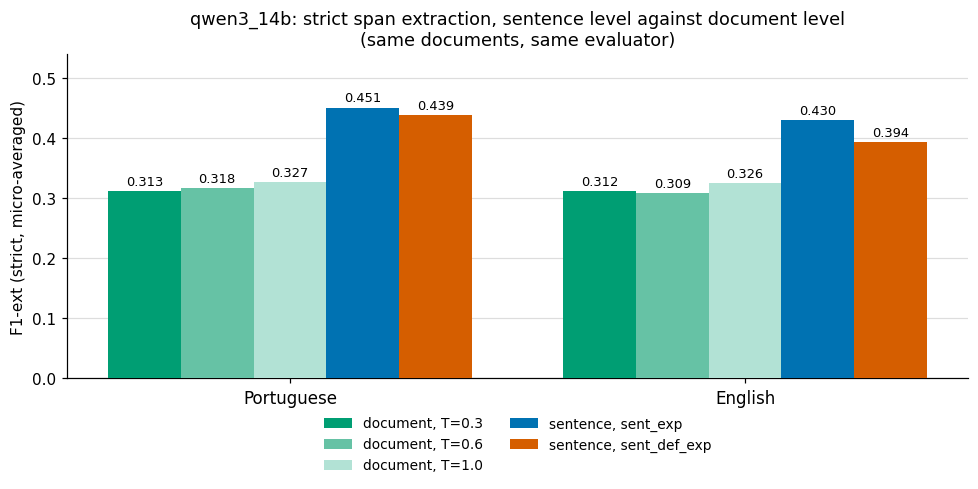

portuguese  document F1-ext 0.3126-0.3273 | sent_exp 0.4512 | sent_def_exp 0.4394
english     document F1-ext 0.3085-0.3259 | sent_exp 0.4303 | sent_def_exp 0.3939


In [7]:
document_scores = c.compute_extraction_classification_metrics(
    document_detailed, group_cols=["language", "temperature"]
)
document_scores["regime"] = "document"
document_scores["run"] = (DOC_TEMPLATE + " T="
                          + document_scores["temperature"].map(lambda t: f"{t:g}"))

sentence_scores = participant_stages.copy()
sentence_scores["regime"] = sentence_scores["condition"]
sentence_scores["temperature"] = SENTENCE_TEMPERATURE
sentence_scores["run"] = sentence_scores["condition"] + " T=0.3"

comparison = pd.concat([document_scores, sentence_scores], ignore_index=True)
comparison = comparison.assign(
    language=pd.Categorical(comparison["language"], categories=c.LANGUAGE_ORDER,
                            ordered=True),
).sort_values(["language", "regime", "temperature"])

display(comparison[["language", "run", "regime", "temperature", "precision_ext",
                    "recall_ext", "f1_ext", "f1_cls", "tp_ext", "fp_ext", "fn_ext"]]
        .round(4).reset_index(drop=True))

# Bars in run order: the three document-level temperatures, then the two
# sentence-level conditions, so the within-regime spread is read before the
# between-regime step.
BAR_ORDER = [f"{DOC_TEMPLATE} T=0.3", f"{DOC_TEMPLATE} T=0.6", f"{DOC_TEMPLATE} T=1",
             "sent_exp T=0.3", "sent_def_exp T=0.3"]
BAR_COLORS = {
    f"{DOC_TEMPLATE} T=0.3": "#009E73",
    f"{DOC_TEMPLATE} T=0.6": "#66C2A5",
    f"{DOC_TEMPLATE} T=1": "#B2E2D5",
    "sent_exp T=0.3": "#0072B2",
    "sent_def_exp T=0.3": "#D55E00",
}
BAR_LABELS = {
    f"{DOC_TEMPLATE} T=0.3": "document, T=0.3",
    f"{DOC_TEMPLATE} T=0.6": "document, T=0.6",
    f"{DOC_TEMPLATE} T=1": "document, T=1.0",
    "sent_exp T=0.3": "sentence, sent_exp",
    "sent_def_exp T=0.3": "sentence, sent_def_exp",
}

fig, ax = plt.subplots(figsize=(9.0, 4.6))
x = np.arange(len(c.LANGUAGE_ORDER))
width = 0.16

for i, run in enumerate(BAR_ORDER):
    offset = (i - (len(BAR_ORDER) - 1) / 2) * width
    values = [comparison[(comparison["language"] == language)
                         & (comparison["run"] == run)]["f1_ext"].iloc[0]
              for language in c.LANGUAGE_ORDER]
    bars = ax.bar(x + offset, values, width, label=BAR_LABELS[run],
                  color=BAR_COLORS[run], zorder=3)
    ax.bar_label(bars, fmt="%.3f", fontsize=8.5, padding=2)

ax.set_xticks(x)
ax.set_xticklabels([language.capitalize() for language in c.LANGUAGE_ORDER], fontsize=11)
ax.set_ylabel("F1-ext (strict, micro-averaged)")
ax.set_ylim(0, 0.54)
ax.legend(frameon=False, fontsize=9, ncol=2, loc="upper center",
          bbox_to_anchor=(0.5, -0.08))
ax.set_title(f"{MODEL}: strict span extraction, sentence level against document level\n"
             f"(same documents, same evaluator)", fontsize=11.5)
c.style_axis(ax)
fig.tight_layout()
c.save_fig(fig, "10_sentence_vs_document_f1", tight=False)
plt.show()

for language in c.LANGUAGE_ORDER:
    sub = comparison[comparison["language"] == language].set_index("run")
    document_range = sub.loc[[r for r in BAR_ORDER if r.startswith(DOC_TEMPLATE)], "f1_ext"]
    print(f"{language:<11} document F1-ext {document_range.min():.4f}-{document_range.max():.4f} "
          f"| sent_exp {sub.loc['sent_exp T=0.3', 'f1_ext']:.4f} "
          f"| sent_def_exp {sub.loc['sent_def_exp T=0.3', 'f1_ext']:.4f}")

---

# Section 3 - Word-level analysis

The strict metric of Section 2 scores a participant as right or wrong and stops
there. The relaxed, word-level evaluation goes one level down and books every word
of a scored prediction as `tp` (present in both), `fp` (added by the model) or `fn`
(annotation word missed). Notebook 09 asks **which word of a participant goes
wrong**; the same question is asked here of the two regimes side by side.

Both sides are read from the **extraction** output - `results/test/` for document
level and `results/sentence_level/ext/` for sentence level - so the word slots
reflect the extraction stage alone, and not any span the later classification stage
dropped. The document-level run is `ext_exp` at *T* = 0.3, the matched
configuration of Section 2.

Each figure has the same two panels as notebook 09: on the left what happened at
each word slot, on the right what the errors at that slot are made of. Bars are
grouped by regime, and the number above each bar is its denominator - slots differ
a great deal in how many words they carry.

**Population.** As in notebook 09, every figure and table of this section is drawn
over the *partially matched* participants only: the pairings booking at least one
`fn` (an annotation word the run did not produce) or at least one `fp` (a word it
added). Participants a run recovered exactly are excluded, because they contribute
nothing but `tp` and their share of a slot answers a different question - *how often
is this slot right overall* rather than *when a participant goes wrong, where does it
go wrong*. The left panel therefore reads as the anatomy of a failure and not as an
accuracy, which is also what makes these figures readable against notebook 09's. The
right panel is unaffected by the restriction either way: an exactly matched pairing
books no `fn` and no `fp`.


In [8]:
document_tokens = pd.concat(
    [c.load_detailed_token("test", language) for language in c.LANGUAGE_ORDER],
    ignore_index=True,
)
document_tokens = c.add_run_config_columns(document_tokens)
document_tokens = document_tokens[
    (document_tokens["model"] == MODEL)
    & (document_tokens["base_template"] == DOC_TEMPLATE)
    & (document_tokens["temperature"] == SENTENCE_TEMPERATURE)
].copy()
document_tokens["regime"] = "document"

sentence_tokens = pd.concat(
    [c.load_detailed_token("sentence_level/ext", language)
     for language in c.LANGUAGE_ORDER],
    ignore_index=True,
)
sentence_tokens = c.add_run_config_columns(sentence_tokens)
# `sent_exp` is written as `ext_exp` in the sentence-level trees; the condition is
# recovered the same way as for the span-level rows above.
sentence_tokens["regime"] = (
    "sent_" + sentence_tokens["base_template"].str.split("_", n=1).str[1]
)
assert set(sentence_tokens["regime"]) == set(CONDITIONS), \
    f"unexpected sentence-level conditions: {sorted(set(sentence_tokens['regime']))}"

tokens = add_positions(pd.concat([document_tokens, sentence_tokens], ignore_index=True))
for regime in REGIME_ORDER:
    check_replay(tokens[tokens["regime"] == regime], regime)

print()
print(tokens.groupby(["language", "regime"], observed=True).size().rename("words").to_string())

# Rows whose prediction matched no annotation above the scorer's threshold have no
# annotation to take a position in (`ann_len == 0`); they are all fp by construction
# and drop out of every per-slot view below.
unmatched = tokens["ann_len"].eq(0)
print(f"\nwords with no matched annotation: {int(unmatched.sum())} "
      f"({unmatched.mean():.1%})")

# The partially matched participants, on the definition notebook 09 uses. Exactly
# recovered participants are dropped here rather than in each figure, so every view
# below shares one population.
pairings = pairing_flags(tokens)
tokens_inexact = inexact_only(tokens)

print()
print(pairings.groupby(["language", "regime"])
      .agg(pairings=("exact", "size"),
           exact=("exact", "sum"),
           inexact=("exact", lambda s: int((~s).sum())))
      .assign(inexact_share=lambda d: (d["inexact"] / d["pairings"]).round(3))
      .to_string())
print(f"\nword rows: {len(tokens)} scored -> {len(tokens_inexact)} "
      f"in partially matched participants")


c:\Users\davib\Desktop\MSc_DataScience\thesis\gpt_struct_me\notebooks\results\.\_common.py:247: DtypeWarning: Columns (6) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(path)


document                           rows=  11263  unrecovered=   0 ( 0.00%)  verdict agreement=100.0000%
sent_exp                           rows=  12158  unrecovered=   0 ( 0.00%)  verdict agreement=100.0000%
sent_def_exp                       rows=  11225  unrecovered=   0 ( 0.00%)  verdict agreement=100.0000%

language    regime      
english     document        5468
            sent_def_exp    5292
            sent_exp        5935
portuguese  document        5795
            sent_def_exp    5933
            sent_exp        6223

words with no matched annotation: 3561 (10.3%)

                         pairings  exact  inexact  inexact_share
language   regime                                               
english    document          1488    723      765          0.514
           sent_def_exp      1587    886      701          0.442
           sent_exp          1725   1010      715          0.414
portuguese document          1519    701      818          0.539
           sent_def_exp  

Saved C:\Users\davib\Desktop\MSc_DataScience\thesis\gpt_struct_me\report\Figures\results\10_word_position_len2_portuguese.pdf


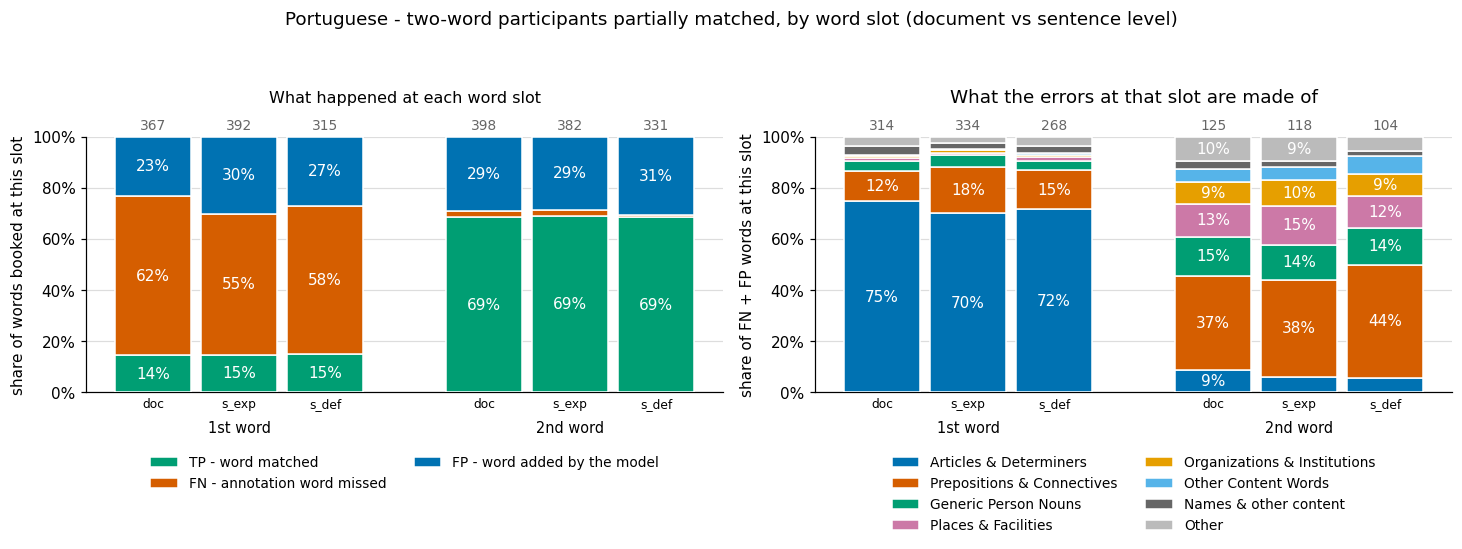

Saved C:\Users\davib\Desktop\MSc_DataScience\thesis\gpt_struct_me\report\Figures\results\10_word_position_len2_english.pdf


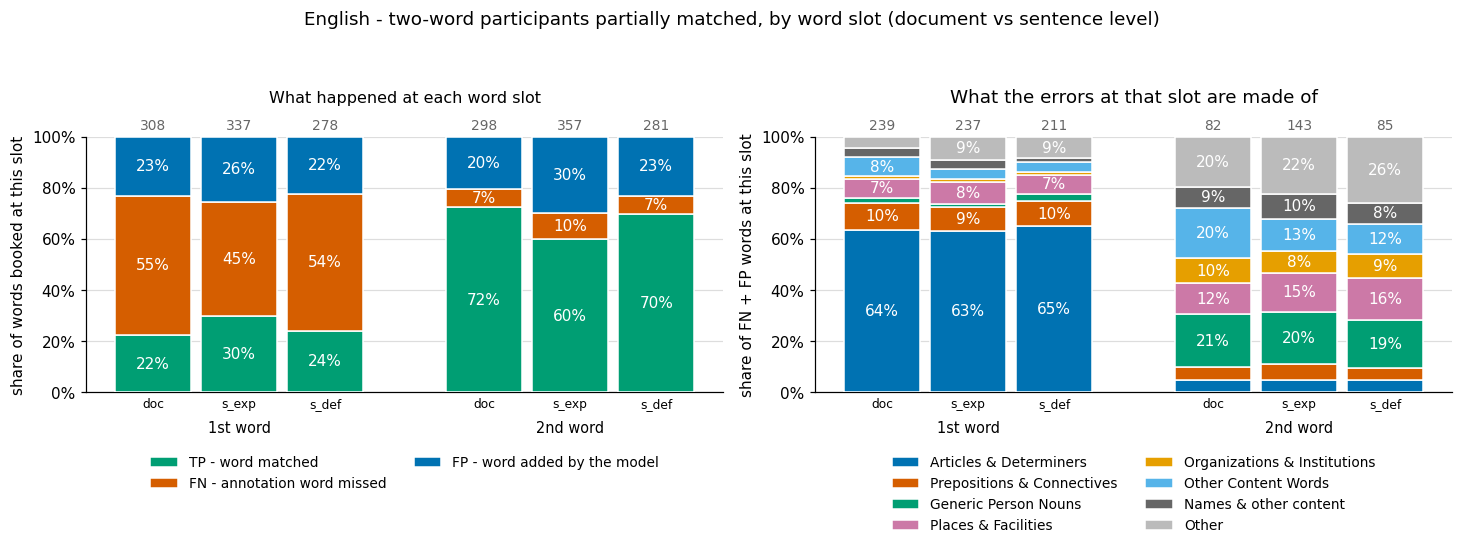

In [9]:
for language in c.LANGUAGE_ORDER:
    position_figure(
        tokens_inexact[tokens_inexact["language"] == language],
        ann_len=2, group_col="regime", groups=REGIME_ORDER,
        title=f"{language.capitalize()} - two-word participants partially matched, "
              f"by word slot (document vs sentence level)",
        filename=f"10_word_position_len2_{language}",
    )


Saved C:\Users\davib\Desktop\MSc_DataScience\thesis\gpt_struct_me\report\Figures\results\10_word_position_len3_portuguese.pdf


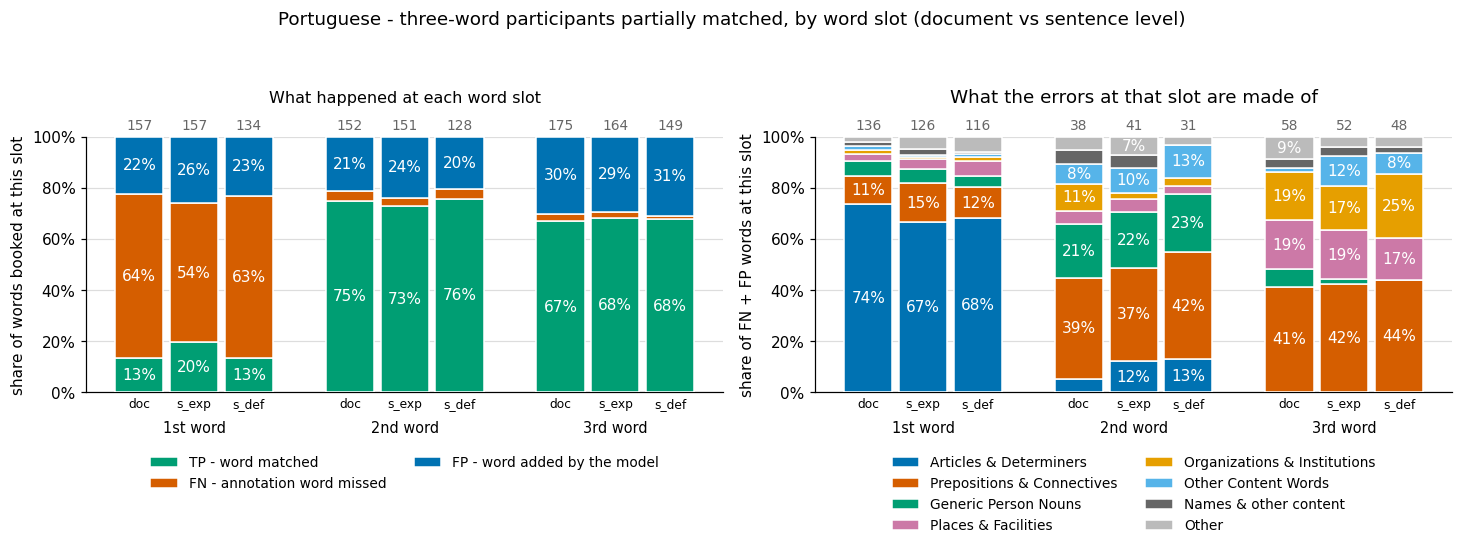

Saved C:\Users\davib\Desktop\MSc_DataScience\thesis\gpt_struct_me\report\Figures\results\10_word_position_len3_english.pdf


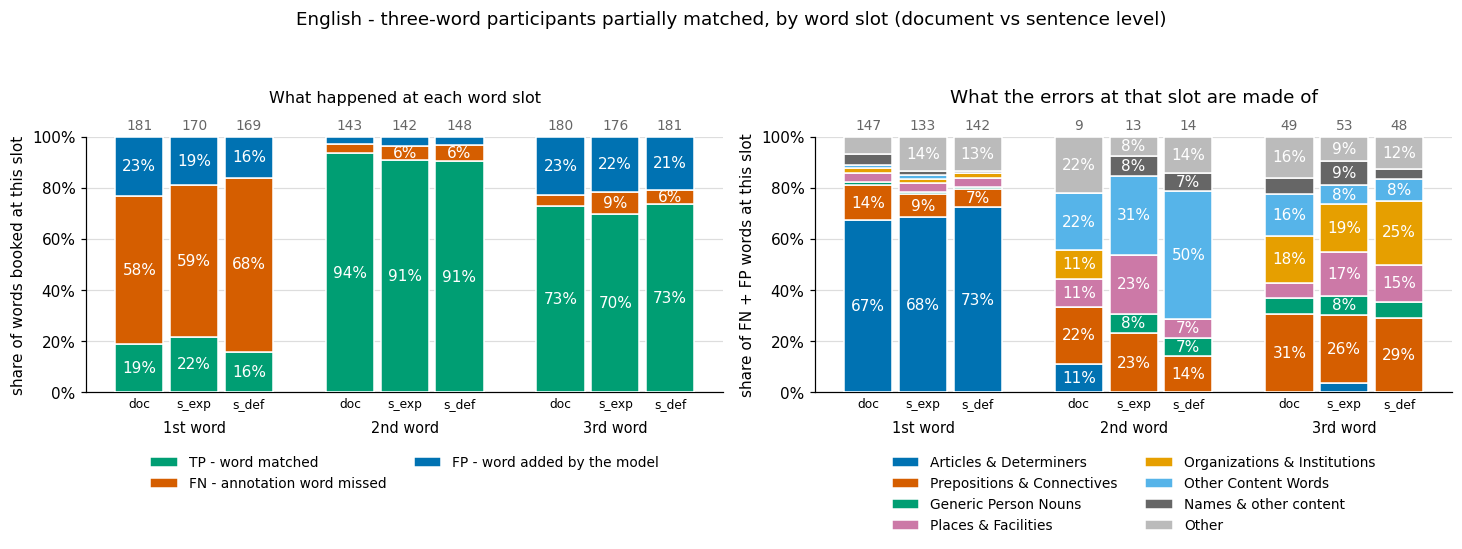

In [10]:
for language in c.LANGUAGE_ORDER:
    position_figure(
        tokens_inexact[tokens_inexact["language"] == language],
        ann_len=3, group_col="regime", groups=REGIME_ORDER,
        title=f"{language.capitalize()} - three-word participants partially matched, "
              f"by word slot (document vs sentence level)",
        filename=f"10_word_position_len3_{language}",
    )


In [11]:
def slot_table(df, ann_len):
    """The numbers behind the left panel, for quoting into the report."""
    sub = df[df["ann_len"] == ann_len]
    counts = (sub.groupby(["language", "regime", "ann_pos"], observed=True)["result"]
              .value_counts().unstack("result")
              .reindex(columns=OUTCOME_ORDER).fillna(0).astype(int))
    counts["total"] = counts.sum(axis=1)
    shares = counts[OUTCOME_ORDER].div(counts["total"], axis=0)
    return counts.join(shares.round(3), rsuffix="_share")


def error_category_table(df, ann_len):
    """The numbers behind the right panel: the lexical make-up of FN + FP words."""
    sub = df[(df["ann_len"] == ann_len) & (df["result"].isin(["fn", "fp"]))]
    counts = (sub.groupby(["language", "regime", "ann_pos", "category"], observed=True)
              .size().unstack("category").fillna(0).astype(int))
    return counts.div(counts.sum(axis=1), axis=0).round(3)


for ann_len in (2, 3):
    print(f"--- {ann_len}-word participants: verdict mix per slot ---")
    display(slot_table(tokens_inexact, ann_len))
    print(f"--- {ann_len}-word participants: lexical make-up of FN + FP per slot ---")
    display(error_category_table(tokens_inexact, ann_len))

--- 2-word participants: verdict mix per slot ---


result                            tp   fn   fp  total  tp_share  fn_share  fp_share
language   regime       ann_pos                                                    
english    document     1         69  168   71    308     0.224     0.545     0.231
                        2        216   21   61    298     0.725     0.070     0.205
           sent_def_exp 1         67  149   62    278     0.241     0.536     0.223
                        2        196   20   65    281     0.698     0.071     0.231
           sent_exp     1        100  151   86    337     0.297     0.448     0.255
                        2        214   37  106    357     0.599     0.104     0.297
portuguese document     1         53  229   85    367     0.144     0.624     0.232
                        2        273    9  116    398     0.686     0.023     0.291
           sent_def_exp 1         47  183   85    315     0.149     0.581     0.270
                        2        227    3  101    331     0.686     0.009     0.305
           sent_exp     1         58  215  119    392     0.148     0.548     0.304
                        2        264    9  109    382     0.691     0.024     0.285

--- 2-word participants: lexical make-up of FN + FP per slot ---


category                         Articles & Determiners  Generic Person Nouns  Names & other content  Numbers & Quantities  Objects & Substances  Organizations & Institutions  Other Content Words  \
language   regime       ann_pos                                                                                                                                                                       
english    document     1                         0.636                 0.021                  0.033                 0.021                 0.008                         0.013                0.075   
                        2                         0.049                 0.207                  0.085                 0.000                 0.085                         0.098                0.195   
           sent_def_exp 1                         0.649                 0.028                  0.014                 0.043                 0.000                         0.014                0.038   
                        2                         0.047                 0.188                  0.082                 0.035                 0.153                         0.094                0.118   
           sent_exp     1                         0.633                 0.013                  0.034                 0.046                 0.000                         0.013                0.038   
                        2                         0.049                 0.203                  0.098                 0.063                 0.119                         0.084                0.126   
portuguese document     1                         0.748                 0.038                  0.038                 0.029                 0.003                         0.006                0.003   
                        2                         0.088                 0.152                  0.032                 0.024                 0.064                         0.088                0.048   
           sent_def_exp 1                         0.716                 0.037                  0.026                 0.019                 0.011                         0.007                0.007   
                        2                         0.058                 0.144                  0.019                 0.010                 0.038                         0.087                0.067   
           sent_exp     1                         0.701                 0.045                  0.024                 0.012                 0.006                         0.009                0.006   
                        2                         0.059                 0.136                  0.025                 0.025                 0.059                         0.102                0.051   

category                         Person Names  Places & Facilities  Prepositions & Connectives  Pronouns  
language   regime       ann_pos                                                                           
english    document     1               0.000                0.071                       0.105     0.017  
                        2               0.098                0.122                       0.049     0.012  
           sent_def_exp 1               0.000                0.071                       0.100     0.043  
                        2               0.071                0.165                       0.047     0.000  
           sent_exp     1               0.000                0.084                       0.093     0.046  
                        2               0.042                0.154                       0.063     0.000  
portuguese document     1               0.000                0.013                       0.118     0.003  
                        2               0.000                0.128                       0.368     0.008  
           sent_def_exp 1               0.000                0.015                       0.153     0.007  
                        2           

--- 3-word participants: verdict mix per slot ---


result                            tp   fn  fp  total  tp_share  fn_share  fp_share
language   regime       ann_pos                                                   
english    document     1         34  105  42    181     0.188     0.580     0.232
                        2        134    5   4    143     0.937     0.035     0.028
                        3        131    8  41    180     0.728     0.044     0.228
           sent_def_exp 1         27  115  27    169     0.160     0.680     0.160
                        2        134    9   5    148     0.905     0.061     0.034
                        3        133   10  38    181     0.735     0.055     0.210
           sent_exp     1         37  101  32    170     0.218     0.594     0.188
                        2        129    8   5    142     0.908     0.056     0.035
                        3        123   15  38    176     0.699     0.085     0.216
portuguese document     1         21  101  35    157     0.134     0.643     0.223
                        2        114    6  32    152     0.750     0.039     0.211
                        3        117    5  53    175     0.669     0.029     0.303
           sent_def_exp 1         18   85  31    134     0.134     0.634     0.231
                        2         97    5  26    128     0.758     0.039     0.203
                        3        101    2  46    149     0.678     0.013     0.309
           sent_exp     1         31   85  41    157     0.197     0.541     0.261
                        2        110    5  36    151     0.728     0.033     0.238
                        3        112    4  48    164     0.683     0.024     0.293

--- 3-word participants: lexical make-up of FN + FP per slot ---


category                         Articles & Determiners  Generic Person Nouns  Names & other content  Numbers & Quantities  Objects & Substances  Organizations & Institutions  Other Content Words  \
language   regime       ann_pos                                                                                                                                                                       
english    document     1                         0.673                 0.014                  0.041                 0.041                 0.000                         0.020                0.014   
                        2                         0.111                 0.000                  0.000                 0.000                 0.000                         0.111                0.222   
                        3                         0.000                 0.061                  0.061                 0.041                 0.061                         0.184                0.163   
           sent_def_exp 1                         0.725                 0.007                  0.007                 0.056                 0.000                         0.021                0.000   
                        2                         0.000                 0.071                  0.071                 0.000                 0.000                         0.000                0.500   
                        3                         0.000                 0.062                  0.042                 0.000                 0.062                         0.250                0.083   
           sent_exp     1                         0.684                 0.008                  0.015                 0.053                 0.000                         0.015                0.015   
                        2                         0.000                 0.077                  0.077                 0.000                 0.000                         0.000                0.308   
                        3                         0.038                 0.075                  0.094                 0.000                 0.057                         0.189                0.075   
portuguese document     1                         0.735                 0.059                  0.015                 0.000                 0.022                         0.015                0.015   
                        2                         0.053                 0.211                  0.053                 0.026                 0.000                         0.105                0.079   
                        3                         0.000                 0.069                  0.034                 0.017                 0.052                         0.190                0.017   
           sent_def_exp 1                         0.681                 0.043                  0.009                 0.026                 0.026                         0.017                0.009   
                        2                         0.129                 0.226                  0.000                 0.000                 0.000                         0.032                0.129   
                        3                         0.000                 0.000                  0.021                 0.000                 0.021                         0.250                0.083   
           sent_exp     1                         0.667                 0.056                  0.024                 0.008                 0.032                         0.008                0.008   
                        2                         0.122                 0.220                  0.049                 0.000                 0.049                         0.024                0.098   
                        3                         0.000                 0.019                  0.038                 0.000                 0.019                         0.173                0.115   

category           

---

# Section 4 - Class-level analysis

The conditional typing accuracy of notebook 03: of the participants a run located,
what share did it also type correctly. Because it is conditional on the span
already being found, it is not affected by the extraction differences of Section 2
and can be compared across runs that locate very different numbers of participants.

As set out at the top, `qwen3_14b` has no document-level classification to be held
against - its document-level variant is extraction-only. The document-level
reference here is therefore the **pooled** result of the eleven (model, language)
runs that do classify in the test phase, which is the set notebook 03 analyses.
That is a comparison against the document-level *field* rather than against this
model's own counterpart, and it is read as such: it says where sentence-level
typing sits relative to what the document-level regime achieves overall, not what
this model would have done under the other regime.

Supports are printed above every bar. Accuracy per class rests on a support that
varies by two orders of magnitude within a panel, so the two are read together.


document-level classifying runs pooled: 12
  portuguese  amalia, euro_llm_9b, gemini, gemma3_12b, gemma3_4b, qwen3_4b
  english     amalia, euro_llm_9b, gemini, gemma3_12b, gemma3_4b, qwen3_4b
Saved C:\Users\davib\Desktop\MSc_DataScience\thesis\gpt_struct_me\report\Figures\results\10_cls_accuracy_by_class.pdf


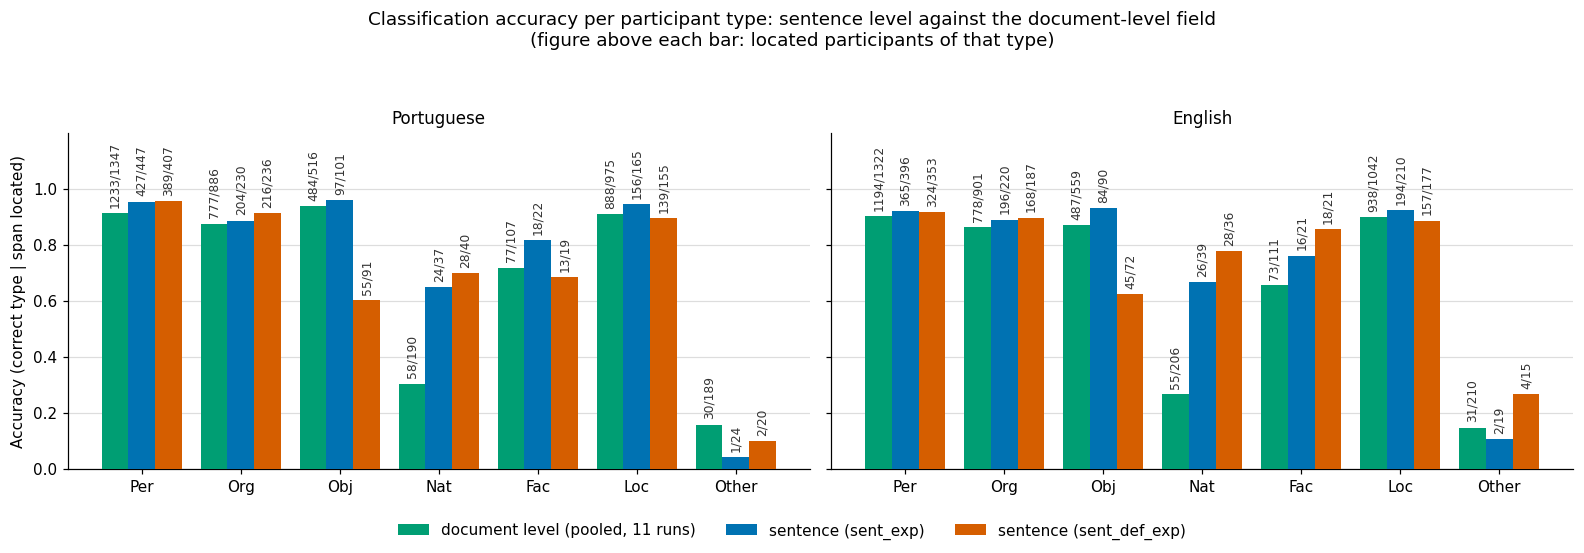


sentence-level aggregate typing accuracy:
  language    condition  n_matched  accuracy  macro_precision  macro_recall  macro_f1
   english sent_def_exp        861  0.864111         0.734171      0.747119  0.729566
   english     sent_exp        995  0.887437         0.716455      0.743372  0.714148
portuguese sent_def_exp        968  0.869835         0.715456      0.693773  0.695194
portuguese     sent_exp       1026  0.903509         0.726472      0.750937  0.719212


recall                                                         support                                                       
language  english                       portuguese                        english                       portuguese                      
regime   document sent_def_exp sent_exp   document sent_def_exp sent_exp document sent_def_exp sent_exp   document sent_def_exp sent_exp
cls                                                                                                                                     
Fac         0.658        0.857    0.762      0.720        0.684    0.818    111.0         21.0     21.0      107.0         19.0     22.0
Loc         0.900        0.887    0.924      0.911        0.897    0.945   1042.0        177.0    210.0      975.0        155.0    165.0
Nat         0.267        0.778    0.667      0.305        0.700    0.649    206.0         36.0     39.0      190.0         40.0     37.0
Obj         0.871        0.625    0.933      0.938        0.604    0.960    559.0         72.0     90.0      516.0         91.0    101.0
Org         0.863        0.898    0.891      0.877        0.915    0.887    901.0        187.0    220.0      886.0        236.0    230.0
Other       0.148        0.267    0.105      0.159        0.100    0.042    210.0         15.0     19.0      189.0         20.0     24.0
Per         0.903        0.918    0.922      0.915        0.956    0.955   1322.0        353.0    396.0     1347.0        407.0    447.0

In [12]:
# The document-level classifying field: the same eleven runs notebook 03 analyses.
best_configs = c.load_best_configs()
all_test = pd.concat(
    [c.load_detailed("test", language) for language in c.LANGUAGE_ORDER],
    ignore_index=True,
)
best_detailed = c.coarsen_types(c.filter_to_best_configs(all_test, best_configs))
field_scores = c.compute_extraction_classification_metrics(
    best_detailed, group_cols=["language", "model"]
)
classifying = set(map(
    tuple,
    field_scores.dropna(subset=["f1_cls"])[["language", "model"]].values,
))
field = best_detailed[[
    key in classifying
    for key in zip(best_detailed["language"], best_detailed["model"])
]]
print(f"document-level classifying runs pooled: {len(classifying)}")
for language in c.LANGUAGE_ORDER:
    models = sorted(m for lang, m in classifying if lang == language)
    print(f"  {language:<11} {', '.join(models)}")

document_by_class = c.compute_conditional_type_metrics(
    field, group_cols=["language"], per_class=True
).assign(regime="document")
sentence_by_class = c.compute_conditional_type_metrics(
    sentence_detailed, group_cols=["language", "condition"], per_class=True
).rename(columns={"condition": "regime"})

by_class = pd.concat([document_by_class, sentence_by_class], ignore_index=True)

CLASSES = c.PROMPT_CLASSES_COARSE
fig, axes = plt.subplots(1, 2, figsize=(14.5, 5.0), sharey=True)
x = np.arange(len(CLASSES))
width = 0.27

for ax, language in zip(axes, c.LANGUAGE_ORDER):
    for i, regime in enumerate(REGIME_ORDER):
        sub = (by_class[(by_class["language"] == language) & (by_class["regime"] == regime)]
               .set_index("cls").reindex(CLASSES))
        offset = (i - 1) * width
        ax.bar(x + offset, sub["recall"].values, width,
               label=("document level (pooled, 11 runs)" if regime == "document"
                      else REGIME_LABELS[regime]),
               color=REGIME_COLORS[regime], zorder=3)
        for xi, value, support, tp in zip(x + offset, sub["recall"].values, sub["support"].values, sub["tp"].values):
            if np.isnan(value):
                continue
            ax.text(xi, value + 0.02, f"{int(tp)}/{int(support)}", ha="center", va="bottom",
                    fontsize=8, rotation=90, color="#333333")
    ax.set_xticks(x)
    ax.set_xticklabels(CLASSES)
    ax.set_ylim(0, 1.20)
    ax.set_yticks(np.arange(0, 1.01, 0.2))
    ax.set_title(language.capitalize(), fontsize=11)
    c.style_axis(ax)

axes[0].set_ylabel("Accuracy (correct type | span located)")
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="lower center", ncol=3, frameon=False)
fig.suptitle("Classification accuracy per participant type: sentence level against "
             "the document-level field\n"
             "(figure above each bar: located participants of that type)", fontsize=12)
fig.tight_layout(rect=(0, 0.07, 1, 0.93))
c.save_fig(fig, "10_cls_accuracy_by_class", tight=False)
plt.show()

# The aggregate the panels decompose, alongside the per-class supports.
aggregate = c.compute_conditional_type_metrics(
    sentence_detailed, group_cols=["language", "condition"]
)
print("\nsentence-level aggregate typing accuracy:")
print(aggregate.to_string(index=False))

pivot = by_class.pivot_table(index="cls", columns=["language", "regime"],
                             values=["recall", "support"])
display(pivot.round(3))

### The per-class counts behind those bars

The figure above scores typing accuracy, which is a ratio, and ratios on the small
types rest on very few participants. The table below drops the ratios and reports
the three counts they are built from, per participant type and per run:

| column | meaning |
| --- | --- |
| `annotated` | participants of that type in the corpus - the same for every run of a language |
| `located` | of those, the ones whose span the run returned exactly |
| `typed` | of the located ones, the ones also given the right type |

Every document-level run that classifies is listed separately rather than pooled,
so the sentence-level rows can be read against the individual models instead of
against an average of them. This is the view carried into the report: with no
document-level classification for `qwen3_14b` itself, counts let the two regimes be
set side by side without asserting a metric comparison the design cannot support.


In [13]:
def class_counts(df, run_cols) -> pd.DataFrame:
    """annotated / located / typed per participant type, for each run."""
    gold_rows = df[df["result"].isin(["tp", "fn"])]
    located_rows = df[df["result"] == "tp"]
    typed_rows = located_rows[located_rows["pred_type"] == located_rows["annt_type"]]
    keys = run_cols + ["annt_type"]
    out = pd.DataFrame({
        "annotated": gold_rows.groupby(keys).size(),
        "located": located_rows.groupby(keys).size(),
        "typed": typed_rows.groupby(keys).size(),
    })
    return out.fillna(0).astype(int).reset_index().rename(columns={"annt_type": "cls"})


document_counts = class_counts(field, ["language", "model"]).rename(columns={"model": "run"})
sentence_counts = class_counts(sentence_detailed, ["language", "condition"]).rename(
    columns={"condition": "run"})
counts = pd.concat([document_counts, sentence_counts], ignore_index=True)
counts = counts[counts["cls"].isin(CLASSES)]

# `annotated` is a property of the corpus, so it must not vary across the runs of a
# language. Asserted, because the report table prints it once per language.
spread = counts.groupby(["language", "cls"])["annotated"].nunique()
assert (spread == 1).all(), \
    f"annotated counts differ across runs: {spread[spread > 1].to_dict()}"

RUN_ORDER = [m for m in c.MODEL_ORDER if m in set(document_counts["run"])] + CONDITIONS
table = (counts
         .assign(run=lambda d: pd.Categorical(d["run"], categories=RUN_ORDER, ordered=True),
                 cls=lambda d: pd.Categorical(d["cls"], categories=CLASSES, ordered=True),
                 language=lambda d: pd.Categorical(d["language"],
                                                   categories=c.LANGUAGE_ORDER, ordered=True))
         .sort_values(["language", "run", "cls"]))

annotated = (table.drop_duplicates(["language", "cls"])
             .pivot(index="language", columns="cls", values="annotated"))
print("annotated participants per type (identical across the runs of a language):")
display(annotated)
print(f"totals: {annotated.sum(axis=1).to_dict()}")

for language in c.LANGUAGE_ORDER:
    print(f"\n--- {language}: located / typed per type ---")
    sub = table[table["language"] == language]
    display(sub.pivot(index="run", columns="cls", values=["located", "typed"])
            .swaplevel(axis=1).sort_index(axis=1, level=0, sort_remaining=False)
            .reindex(columns=CLASSES, level=0).dropna(how="all"))

class_count_table = table.reset_index(drop=True)

annotated participants per type (identical across the runs of a language):


cls,Per,Org,Obj,Nat,Fac,Loc,Other
language,,,,,,,
portuguese,788,584,303,101,73,508,212
english,788,573,304,101,73,516,213


totals: {'portuguese': 2569, 'english': 2568}

--- portuguese: located / typed per type ---


cls              Per           Org           Obj           Nat           Fac           Loc         Other      
             located typed located typed located typed located typed located typed located typed located typed
run                                                                                                           
gemini           486   473     306   275     199   192      69    45      38    34     268   244      59    16
gemma3_4b        165   144     118   103      61    61      24     3      10     4     138   129      25     2
gemma3_12b       281   249     140   123      98    92      29     1      19    13     167   151      35    11
qwen3_4b         162   147     108    97      58    55      22     3      13    10     164   151      25     1
amalia           102    90      86    69      35    33      20     6      11     6      88    81      18     0
euro_llm_9b      151   130     128   110      65    51      26     0      16    10     150   132      28     0
sent_exp         447   427     230   204     101    97      37    24      22    18     165   156      24     1
sent_def_exp     407   389     236   216      91    55      40    28      19    13     155   139      20     2


--- english: located / typed per type ---


cls              Per           Org           Obj           Nat           Fac           Loc         Other      
             located typed located typed located typed located typed located typed located typed located typed
run                                                                                                           
gemini           456   437     302   264     185   172      68    43      35    27     296   264      63    17
gemma3_4b        161   145     127   116      64    53      29     3      16    11     156   147      22     4
gemma3_12b       284   262     185   164     124   103      39     2      19    12     186   166      35     9
qwen3_4b         223   200     126   109      95    85      28     7      18    13     181   161      46     0
amalia            40    37      54    48      17    10      11     0       4     0      62    52       6     1
euro_llm_9b      158   113     107    77      74    64      31     0      19    10     161   148      38     0
sent_exp         396   365     220   196      90    84      39    26      21    16     210   194      19     2
sent_def_exp     353   324     187   168      72    45      36    28      21    18     177   157      15     4

---

## Synthesis

**The detector is not where the cascade loses its material.** Detection recall runs
from 0.849 to 0.935 across the four cells of Section 1, so between 85% and 94% of
the sentences that actually carry an annotated participant are passed on. Whatever
the regime gets wrong, it does not mostly get wrong by refusing to read the
sentence.

**Sentence level extracts more than document level, in both languages.** Section 2
holds the model, the documents, the evaluator and the temperature constant and
moves only the regime. F1-ext rises from 0.313 to 0.451 in Portuguese and from
0.312 to 0.430 in English, and the gain is not a trade: precision and recall both
improve. Splitting the article into sentences puts more participants on the table
*and* raises the share of what it returns that is right. The three document-level
temperatures span 0.309 to 0.327, so the regime moves the score by several times
what the decoding parameter does.

**The comparison between the two prompt conditions is confounded and should not be
read as a prompt effect.** `sent_exp` outscores `sent_def_exp` on F1-ext and F1-cls
in both languages, but it was also shown one sentence more per document -- the
headline -- which `sent_def_exp` never sees. Only 10 Portuguese and 11 English
participants are reachable *only* from the headline, so the ceiling this puts on
recall is slight; but 234 and 225 of them appear in it, and a headline is a short,
dense second chance at participants the body also carries. The two conditions
differ in their material as well as in their prompts.

**The regime supplies a type where the document-level counterpart supplies none.**
The comparison that cannot be drawn is itself a finding: `qwen3_14b` reaches the
document-level test stage on an extraction-only variant, so its document-level runs
carry no attribute information at all, while the sentence-level cascade returns a
type for every span it keeps and gets most of them right.

**Typing is not the bottleneck under either regime, and sentence level types
better.** Conditional accuracy is 0.870 and 0.904 in Portuguese and 0.862 and 0.887
in English, against 0.843 and 0.796 for the pooled document-level field -- above
every individual document-level run except `gemini` in Portuguese, which
`sent_exp` still edges. The per-class profile is mostly the familiar one, with
`Per`, `Org` and `Loc` high everywhere and `Other` collapsing at both levels. Two
types depart from it. `Nat` is barely assigned by the document-level field at all
(0.087 in English, 0.305 in Portuguese) and is typed at 0.649 to 0.778 by the
sentence-level runs -- on smaller supports, but not small enough to explain the
distance. `Obj` moves the other way and splits the two conditions: document level
and `sent_exp` both type it above 0.85, while `sent_def_exp` drops to 0.604 in
Portuguese and 0.625 in English, the largest gap between the conditions anywhere in
the figure. Asking for the type of a span already in hand, in a sentence of
context, is generally an easier question than asking for it as part of a
whole-article answer, but the definition-carrying prompt does not benefit from it
evenly across the types.

**The ceiling stays at span identification.** Both regimes locate well under half
the annotated participants and type most of what they locate. Section 3, read over
the partially matched participants alone, puts the loss at the first word under both
regimes: the `fn` share is highest at slot 1 in every cell -- 0.45 to 0.62 on
two-word participants and 0.54 to 0.68 on three-word ones, against 0.01 to 0.10 at
the last slot -- and articles and determiners make up between two thirds and three
quarters of the errors there. Sentence level does not lift that. It narrows the
slot-1 `fn` share on two-word participants in both languages (0.545 to 0.448 in
English, 0.624 to 0.548 in Portuguese, `sent_exp` against document level), but on
three-word participants both English sentence runs sit *above* the document-level
one (0.594 and 0.680 against 0.580) while the Portuguese ones stay at or below it.
The first-word boundary is a property of the task these prompts share rather than of
the regime.

Sentence level does recover more participants exactly, which is the same finding
from the other side: 41-44% of its scored pairings are inexact against 51-54% of the
document-level ones.
